# 연체 예측 최종 모델 독립 실행
이 노트북은 전처리부터 최종 모델 학습, 소프트보팅, 평가까지 **위에서 아래로 실행**하는 최종본입니다. 기존 `1_3.ipynb`, 별도 Python 모듈, 저장 모델, 실험 결과 폴더가 필요하지 않습니다.

**준비물:** 이 노트북과 원본 `cs-training.csv`를 같은 폴더에 둡니다. 그 폴더에서 Jupyter를 열고 **커널 재시작 후 전체 실행**합니다. CSV를 다른 위치에 두었다면 2절의 `DATA_PATH`만 바꾸면 됩니다.

**재현 목표:** 검증 AP **0.4196579357 ≈ 0.419658**. XGBoost 32% + LightGBM 48% + 랜덤 포레스트 20%의 확률을 평균합니다. 이 수치는 테스트 성능이 아닙니다. 학습·검증·테스트를 60:20:20으로 분리하되 테스트는 보관만 하고 평가하지 않습니다.

전체 튜닝을 다시 수행하지 않고, 이미 선택한 최종 설정만 학습하므로 실행 흐름이 짧습니다. 중간 실험의 핵심 기록은 맨 아래에 정리했습니다.

## 1 실행 환경
Python **3.10**에서 확인한 원래 패키지 버전은 아래와 같습니다. 같은 데이터·버전·시드를 사용해야 기존 수치를 가장 가깝게 재현할 수 있습니다. 최신 라이브러리는 기본값이나 학습 구현이 달라 점수가 달라질 수 있습니다.

| 패키지 | 재현 환경 |
|---|---|
| numpy | 1.23.5 |
| pandas | 1.5.3 |
| scikit-learn | 1.0.2 |
| xgboost | 1.7.6 |
| lightgbm | 4.5.0 |
| matplotlib | 3.6.3 |
| joblib | 1.6.0 |

패키지가 없다면 Python 3.10 환경을 선택한 후 터미널에서 아래 명령을 실행하고 커널을 다시 시작합니다. 이미 설치된 환경에서는 설치할 필요가 없습니다.

```text
python -m pip install numpy==1.23.5 pandas==1.5.3 scikit-learn==1.0.2 xgboost==1.7.6 lightgbm==4.5.0 matplotlib==3.6.3 joblib==1.6.0
```

그래프는 운영체제와 한글 폰트 설치 여부에 영향을 덜 받도록 영문 축 이름을 사용합니다.

In [1]:
from pathlib import Path
import sys
import warnings
import hashlib
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score, log_loss,
    confusion_matrix, precision_recall_curve, roc_curve,
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
N_JOBS = 4
EXPECTED_AP = 0.4196579357385778
EXPECTED_VERSIONS = {
    "numpy": "1.23.5", "pandas": "1.5.3", "scikit-learn": "1.0.2",
    "xgboost": "1.7.6", "lightgbm": "4.5.0",
    "matplotlib": "3.6.3", "joblib": "1.6.0",
}
environment = pd.DataFrame([
    {"package": name, "current": metadata.version(name), "reference": version}
    for name, version in EXPECTED_VERSIONS.items()
])
print("Python:", sys.version.split()[0])
display(environment)
if not (environment["current"] == environment["reference"]).all():
    warnings.warn("현재 패키지 버전이 재현 환경과 다릅니다. AP가 달라지면 버전부터 확인하세요.")
plt.rcParams["axes.unicode_minus"] = False

Python: 3.10.11


,package,current,reference
0,numpy,1.23.5,1.23.5
1,pandas,1.5.3,1.5.3
2,scikit-learn,1.0.2,1.0.2
3,xgboost,1.7.6,1.7.6
4,lightgbm,4.5.0,4.5.0
5,matplotlib,3.7.5,3.6.3
6,joblib,1.6.0,1.6.0


C:\Users\KDS38\AppData\Local\Temp\ipykernel_8436\4249241964.py:39: UserWarning: 현재 패키지 버전이 재현 환경과 다릅니다. AP가 달라지면 버전부터 확인하세요.
  warnings.warn("현재 패키지 버전이 재현 환경과 다릅니다. AP가 달라지면 버전부터 확인하세요.")


## 2 원본 데이터와 전처리
원본 행 번호는 입력 변수에서 제외하고, 나이가 0인 행을 제거합니다. 연체 횟수의 특이값 96·98은 기존 프로젝트의 규칙으로 처리하고, 처리 전 값을 나타내는 `이상` 변수를 만듭니다.

이 특이값 처리 규칙은 기존 실험을 재현하기 위한 프로젝트 규칙입니다. 새로 최적성을 입증한 규칙은 아닙니다. 결측값의 중앙값은 아직 계산하지 않고, 학습 단계의 파이프라인 안에서 계산합니다.

In [2]:
# 데이터가 다른 폴더에 있다면 이 경로만 수정합니다.
DATA_PATH = Path("cs-training.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "cs-training.csv를 노트북과 같은 작업 폴더에 두거나 DATA_PATH를 수정하세요. "
        + "현재 작업 폴더: " + str(Path.cwd())
    )

raw = pd.read_csv(DATA_PATH)
required = [
    "SeriousDlqin2yrs", "RevolvingUtilizationOfUnsecuredLines", "age",
    "NumberOfTime30-59DaysPastDueNotWorse", "DebtRatio", "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans", "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines", "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",
]
missing_columns = sorted(set(required) - set(raw.columns))
if missing_columns:
    raise ValueError("원본 학습 CSV의 필수 열이 없습니다: " + str(missing_columns))
data = raw.drop(columns=["Unnamed: 0"], errors="ignore").copy()
data = data.loc[data["age"] != 0].reset_index(drop=True)
translations = {
    "SeriousDlqin2yrs": "2년 내 심각한 연체 여부",
    "RevolvingUtilizationOfUnsecuredLines": "무담보 신용한도 사용률",
    "age": "나이",
    "NumberOfTime30-59DaysPastDueNotWorse": "30~59일 연체 횟수",
    "DebtRatio": "부채 비율", "MonthlyIncome": "월 소득",
    "NumberOfOpenCreditLinesAndLoans": "개설된 신용거래 수",
    "NumberOfTimes90DaysLate": "90일 이상 연체 횟수",
    "NumberRealEstateLoansOrLines": "부동산 대출·신용한도 수",
    "NumberOfTime60-89DaysPastDueNotWorse": "60~89일 연체 횟수",
    "NumberOfDependents": "부양가족 수",
}
data = data.rename(columns=translations)
data["이상"] = np.select(
    [data["30~59일 연체 횟수"].eq(96), data["30~59일 연체 횟수"].eq(98)],
    [1, 2], default=0,
)
for column in ["30~59일 연체 횟수", "90일 이상 연체 횟수"]:
    data.loc[data[column].isin([96, 98]), column] = 24
data.loc[data["60~89일 연체 횟수"].isin([96, 98]), "60~89일 연체 횟수"] = 12

TARGET = "2년 내 심각한 연체 여부"
X = data.drop(columns=[TARGET]).copy()
y = data[TARGET].astype(int).copy()
assert set(y.unique()) == {0, 1}
print("원본 / 전처리 후 행 수:", len(raw), "/", len(data))
print("입력 변수 수:", X.shape[1], "/ 전체 양성 비율:", round(float(y.mean()), 6))
display(pd.DataFrame({"dtype": X.dtypes.astype(str), "missing": X.isna().sum()}))
# 파일 지문을 남겨 서로 같은 데이터 파일인지 확인할 수 있습니다.
print("CSV SHA256:", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())

원본 / 전처리 후 행 수: 150000 / 149999
입력 변수 수: 11 / 전체 양성 비율: 0.06684


,dtype,missing
무담보 신용한도 사용률,float64,0
나이,int64,0
30~59일 연체 횟수,int64,0
부채 비율,float64,0
월 소득,float64,29731
개설된 신용거래 수,int64,0
90일 이상 연체 횟수,int64,0
부동산 대출·신용한도 수,int64,0
60~89일 연체 횟수,int64,0
부양가족 수,float64,3924


CSV SHA256: 1bd46da486a5708c58c7b01a034fae2a13b327f6f7b62ea7ba4fe3b5824b24ac


## 3 학습과 검증 데이터 분리
기존 프로젝트와 **분할 순서까지 동일하게** 유지합니다. 먼저 테스트 20%를 보관하고, 나머지 80%의 25%를 검증으로 분리합니다. 양성 비율을 유지하는 층화 분할과 시드 42를 사용합니다.

학습은 89,999행, 검증은 30,000행입니다. `X_test`와 `y_test`는 이후 코드에서 예측·평가에 사용하지 않습니다.

In [3]:
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development, y_development, test_size=0.25,
    random_state=SEED, stratify=y_development,
)
assert X_train.index.intersection(X_valid.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_valid.index.intersection(X_test.index).empty
if (len(X_train), len(X_valid), len(X_test)) != (89999, 30000, 30000):
    warnings.warn("기존 데이터 행 수와 다릅니다. 원본 CSV가 같은지 확인하세요.")
display(pd.DataFrame({
    "split": ["train", "validation", "test reserved"],
    "rows": [len(X_train), len(X_valid), len(X_test)],
    "used_for": ["model fitting", "AP and metric evaluation", "not evaluated"],
}))
print("학습 양성 비율:", float(y_train.mean()), "/ 검증 양성 비율:", float(y_valid.mean()))
positive_weight = float((y_train == 0).sum() / (y_train == 1).sum())
print("XGBoost scale_pos_weight:", positive_weight)

,split,rows,used_for
0,train,89999,model fitting
1,validation,30000,AP and metric evaluation
2,test reserved,30000,not evaluated


학습 양성 비율: 0.06684518716874632 / 검증 양성 비율: 0.06683333333333333
XGBoost scale_pos_weight: 13.959940159574469


## 4 최종 모델 설정
각 모델은 **학습 데이터의 중앙값으로 결측값을 대체**하고 결측 여부 지표를 추가합니다. 검증 데이터로 중앙값을 구하지 않습니다. 트리 기반 모델이므로 별도 표준화는 적용하지 않습니다.

| 모델 | 핵심 설정 | 보팅 비중 |
|---|---|---:|
| XGBoost | 학습률 0.02, 트리 350, 깊이 4, min_child_weight 15 | 32% |
| LightGBM | 학습률 0.027, 트리 350, num_leaves 12, reg_alpha 0.1 | 48% |
| Random Forest | 트리 200, 깊이 12, 리프 최소 30, 행 샘플 70% | 20% |

아래 코드는 모든 설정을 직접 정의하므로 기존 프로젝트 변수나 저장 파일을 읽지 않습니다.

In [4]:
def make_tree_pipeline(estimator):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", estimator),
    ])

models = {
    "XGBoost": make_tree_pipeline(XGBClassifier(
        n_estimators=350, learning_rate=0.02, max_depth=4,
        min_child_weight=15, subsample=0.8601, colsample_bytree=0.67611,
        scale_pos_weight=positive_weight, reg_lambda=1.0, reg_alpha=0.0,
        gamma=0.0, objective="binary:logistic", eval_metric="aucpr",
        tree_method="hist", base_score=0.5, n_jobs=N_JOBS, random_state=SEED,
    )),
    "LightGBM": make_tree_pipeline(LGBMClassifier(
        boosting_type="gbdt", n_estimators=350, learning_rate=0.027,
        num_leaves=12, max_depth=-1, min_child_samples=150,
        min_child_weight=0.001, min_split_gain=0.0,
        reg_lambda=10.0, reg_alpha=0.1, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.6, class_weight="balanced",
        n_jobs=N_JOBS, random_state=SEED, verbosity=-1,
    )),
    "RandomForest": make_tree_pipeline(RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=30,
        min_samples_split=2, max_features="sqrt", max_samples=0.7,
        class_weight=None, bootstrap=True, criterion="gini",
        n_jobs=N_JOBS, random_state=SEED,
    )),
}
WEIGHTS = {"XGBoost": 0.32, "LightGBM": 0.48, "RandomForest": 0.20}
assert np.isclose(sum(WEIGHTS.values()), 1.0)
display(pd.DataFrame([
    {"model": name, "weight": WEIGHTS[name],
     "n_estimators": pipeline.named_steps["model"].n_estimators}
    for name, pipeline in models.items()
]))

,model,weight,n_estimators
0,XGBoost,0.32,350
1,LightGBM,0.48,350
2,RandomForest,0.20,200


## 5 세 모델 학습과 소프트보팅
각 모델을 학습 데이터로만 학습합니다. 양성 클래스 1의 예측 확률을 구한 후 가중 평균합니다.

**최종 점수 = XGBoost 확률 × 0.32 + LightGBM 확률 × 0.48 + RF 확률 × 0.20**

별도 메타 모델을 학습하지 않는 소프트보팅입니다. 클래스 가중치를 쓴 모델의 출력이 포함되어 있으므로 이 점수를 보정된 실제 연체 발생률로 단정하지 않습니다.

In [5]:
def positive_probability(fitted_model, features):
    positive_column = int(np.flatnonzero(fitted_model.classes_ == 1)[0])
    return fitted_model.predict_proba(features)[:, positive_column]

valid_probabilities = {}
single_results = []
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    probability = positive_probability(pipeline, X_valid)
    assert np.isfinite(probability).all()
    valid_probabilities[name] = probability
    ap = average_precision_score(y_valid, probability)
    single_results.append({"model": name, "validation_AP": ap})
    print(name + " 학습 완료 / 검증 AP: " + format(ap, ".9f"))

voting_probability = sum(
    WEIGHTS[name] * valid_probabilities[name] for name in WEIGHTS
)
voting_ap = float(average_precision_score(y_valid, voting_probability))
comparison = pd.DataFrame(single_results + [
    {"model": "SoftVoting 32:48:20", "validation_AP": voting_ap},
])
display(comparison.round(9))
print("재현 AP:", format(voting_ap, ".12f"))
print("기존 기록과의 차이:", format(voting_ap - EXPECTED_AP, "+.12f"))
if not np.isclose(voting_ap, EXPECTED_AP, rtol=0, atol=1e-8):
    warnings.warn("기존 AP와 차이가 있습니다. CSV 지문, 패키지 버전, 분할과 설정을 확인하세요.")

XGBoost 학습 완료 / 검증 AP: 0.417417678
LightGBM 학습 완료 / 검증 AP: 0.416170759
RandomForest 학습 완료 / 검증 AP: 0.417553057


,model,validation_AP
0,XGBoost,0.417418
1,LightGBM,0.416171
2,RandomForest,0.417553
3,SoftVoting 32:48:20,0.419658


재현 AP: 0.419657935739
기존 기록과의 차이: +0.000000000000


## 6 전체 평가 지표와 임계값
정확도·정밀도·재현율·특이도·F1은 임계값에 따라 달라집니다. 기본 임계값 0.5와 **같은 검증 데이터에서 F1이 최대인 임계값**을 나란히 표시합니다.

AP와 ROC-AUC는 높을수록, Log Loss는 낮을수록 좋습니다. 이 세 지표는 확률로 계산하므로 분류 임계값을 바꿔도 같습니다. F1 최적 임계값은 검증 데이터로 선택했으므로 운영 최적 임계값이나 새 데이터 성능을 보장하지 않습니다.

In [6]:
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_valid, voting_probability)
f1_candidates = (
    2 * pr_precision[:-1] * pr_recall[:-1]
    / np.maximum(pr_precision[:-1] + pr_recall[:-1], 1e-15)
)
selected_threshold = float(pr_thresholds[int(np.argmax(f1_candidates))])

def evaluate_at_threshold(probability, threshold):
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, prediction, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "Accuracy": accuracy_score(y_valid, prediction),
        "Precision": precision_score(y_valid, prediction, zero_division=0),
        "Recall": recall_score(y_valid, prediction, zero_division=0),
        "Specificity": float(tn / (tn + fp)),
        "F1": f1_score(y_valid, prediction, zero_division=0),
        "ROC_AUC": roc_auc_score(y_valid, probability),
        "AP": average_precision_score(y_valid, probability),
        "Log_Loss": log_loss(y_valid, probability, labels=[0, 1]),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

metrics = pd.DataFrame({
    "threshold 0.5": evaluate_at_threshold(voting_probability, 0.5),
    "validation F1 maximum": evaluate_at_threshold(voting_probability, selected_threshold),
}).T
display(metrics[["threshold","Accuracy","Precision","Recall","Specificity","F1","ROC_AUC","AP","Log_Loss"]].T.round(6))
display(metrics[["TN","FP","FN","TP"]].astype(int))
print("검증 F1 최대 임계값:", format(selected_threshold, ".12f"))

,threshold 0.5,validation F1 maximum
threshold,0.500000,0.654735
Accuracy,0.855533,0.917967
Precision,0.272869,0.410798
Recall,0.697756,0.523691
Specificity,0.866833,0.946205
F1,0.392316,0.460425
ROC_AUC,0.867908,0.867908
AP,0.419658,0.419658
Log_Loss,0.354466,0.354466


,TN,FP,FN,TP
threshold 0.5,24267,3728,606,1399
validation F1 maximum,26489,1506,955,1050


검증 F1 최대 임계값: 0.654734857801


## 7 성능을 그래프로 확인
첫 그림은 모델별 AP를 비교하고, 두 번째 그림은 임계값을 바꾸었을 때 정밀도·재현율·F1이 어떻게 달라지는지 보여줍니다. 혼동행렬은 검증 F1 최대 임계값을 적용한 결과입니다.

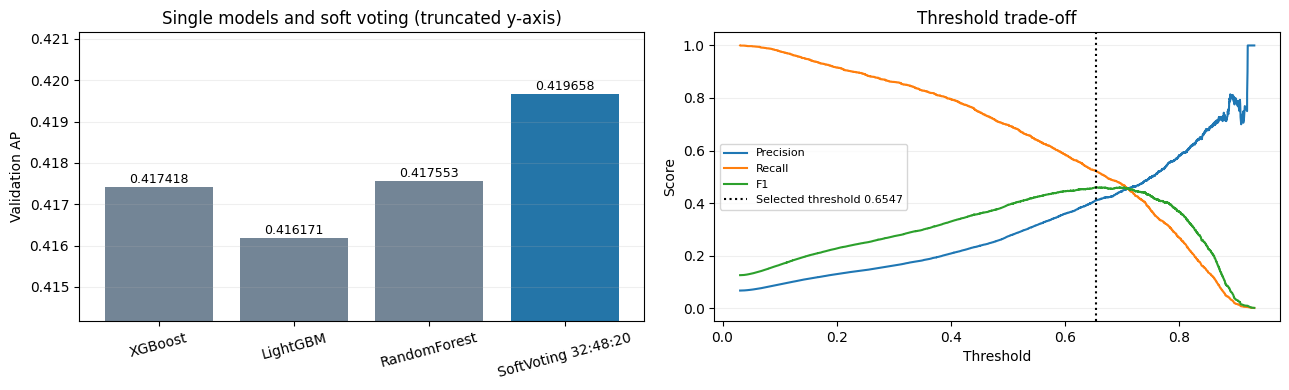

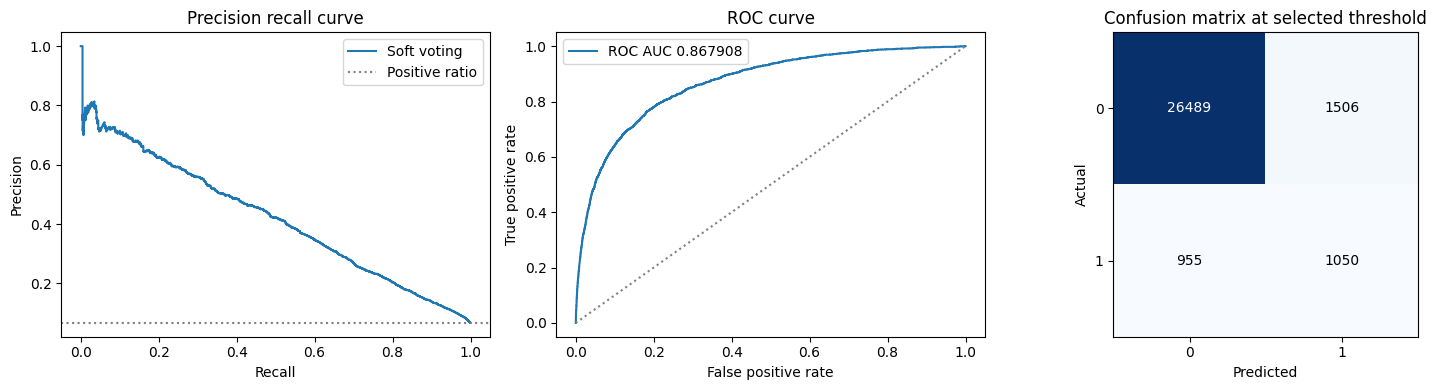

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bars = axes[0].bar(comparison["model"], comparison["validation_AP"],
                   color=["#738596", "#738596", "#738596", "#2475a8"])
for bar, value in zip(bars, comparison["validation_AP"]):
    axes[0].text(bar.get_x()+bar.get_width()/2, value+0.0001,
                 format(value, ".6f"), ha="center", fontsize=9)
axes[0].set_ylim(comparison["validation_AP"].min()-0.002, voting_ap+0.0015)
axes[0].set_ylabel("Validation AP")
axes[0].set_title("Single models and soft voting (truncated y-axis)")
axes[0].tick_params(axis="x", labelrotation=15)
axes[1].plot(pr_thresholds, pr_precision[:-1], label="Precision")
axes[1].plot(pr_thresholds, pr_recall[:-1], label="Recall")
axes[1].plot(pr_thresholds, f1_candidates, label="F1")
axes[1].axvline(selected_threshold, color="black", linestyle=":",
                label="Selected threshold " + format(selected_threshold, ".4f"))
axes[1].set(xlabel="Threshold", ylabel="Score", title="Threshold trade-off")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(pr_recall, pr_precision, label="Soft voting")
axes[0].axhline(float(y_valid.mean()), color="gray", linestyle=":", label="Positive ratio")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision recall curve")
axes[0].legend()
fpr, tpr, _ = roc_curve(y_valid, voting_probability)
axes[1].plot(fpr, tpr, label="ROC AUC " + format(roc_auc_score(y_valid, voting_probability), ".6f"))
axes[1].plot([0, 1], [0, 1], linestyle=":", color="gray")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[1].legend()
cm = confusion_matrix(y_valid, voting_probability >= selected_threshold, labels=[0, 1])
axes[2].imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    axes[2].text(j, i, str(value), ha="center", va="center",
                 color="white" if value > cm.max()/2 else "black")
axes[2].set(xticks=[0,1], yticks=[0,1], xlabel="Predicted", ylabel="Actual",
            title="Confusion matrix at selected threshold")
fig.tight_layout()
plt.show()

## 8 학습 데이터 내부 교차검증
최종 설정과 가중치를 고정한 상태에서 학습 데이터 내부의 층화 3-fold AP를 확인합니다. 매 fold마다 중앙값 대체와 세 모델 학습을 처음부터 수행합니다. 검증·테스트 데이터로 학습하지 않습니다.

기존 기록에서 최종 보팅 평균 AP는 **0.395897**이었고, 직전 보팅은 **0.395875**로 거의 같았습니다. 검증 AP 최고점 상승만으로 일반화 성능 향상을 확정하지 않습니다. 이 과정은 이미 선택한 설정의 보조 확인이며, 탐색 전체를 감싼 nested CV가 아닙니다.

이 셀은 세 모델을 세 번씩 학습하므로 앞의 최종 모델 학습보다 오래 걸립니다. `RUN_CV=False`로 두면 생략할 수 있습니다.

In [8]:
RUN_CV = True
cv_results = None
if RUN_CV:
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    cv_rows = []
    for fold, (train_index, valid_index) in enumerate(cv.split(X_train, y_train), 1):
        fold_probabilities = {}
        for name, template in models.items():
            fold_model = clone(template)
            fold_model.fit(X_train.iloc[train_index], y_train.iloc[train_index])
            fold_probabilities[name] = positive_probability(fold_model, X_train.iloc[valid_index])
        fold_vote = sum(WEIGHTS[name] * fold_probabilities[name] for name in WEIGHTS)
        row = {"fold": fold}
        for name, probability in fold_probabilities.items():
            row[name] = average_precision_score(y_train.iloc[valid_index], probability)
        row["SoftVoting"] = average_precision_score(y_train.iloc[valid_index], fold_vote)
        cv_rows.append(row)
        print("Fold", fold, "soft voting AP:", format(row["SoftVoting"], ".6f"))
    cv_results = pd.DataFrame(cv_rows).set_index("fold")
    display(cv_results.round(6))
    display(pd.DataFrame({
        "mean_AP": cv_results.mean(),
        "std_AP": cv_results.std(ddof=1),
    }).round(6))
else:
    print("교차검증을 생략했습니다. RUN_CV=True로 바꾸면 실행됩니다.")

Fold 1 soft voting AP: 0.403388
Fold 2 soft voting AP: 0.399024
Fold 3 soft voting AP: 0.385278


,XGBoost,LightGBM,RandomForest,SoftVoting
fold,,,,
1,0.399904,0.402995,0.399491,0.403388
2,0.397108,0.391279,0.399197,0.399024
3,0.388750,0.387919,0.377063,0.385278


,mean_AP,std_AP
XGBoost,0.395254,0.005804
LightGBM,0.394064,0.007915
RandomForest,0.391917,0.012865
SoftVoting,0.395897,0.009452


## 9 결과 저장
아래 셀은 실행한 컴퓨터의 `final_model_outputs` 폴더에 지표·검증 예측·모델과 가중치를 저장합니다. 이 폴더는 **실행 결과**로 생성되며, 노트북 실행을 위해 미리 준비할 필요가 없습니다.

저장한 모델은 학습 데이터로만 학습한 모델입니다. 학습+검증으로 다시 학습한 배포 모델이 아닙니다. 모델 파일은 신뢰할 수 있는 파일만 불러오고, 다른 컴퓨터에서는 같은 라이브러리 버전을 사용하는 것이 좋습니다.

In [9]:
import json
import joblib

OUTPUT_DIR = Path("final_model_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
comparison.to_csv(OUTPUT_DIR / "model_AP.csv", index=False, encoding="utf-8-sig")
metrics.to_csv(OUTPUT_DIR / "validation_metrics.csv", encoding="utf-8-sig")
environment.to_csv(OUTPUT_DIR / "environment.csv", index=False, encoding="utf-8-sig")
pd.DataFrame({
    "original_row_index": X_valid.index,
    "actual": y_valid.to_numpy(),
    "voting_score": voting_probability,
}).to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False, encoding="utf-8-sig")
if cv_results is not None:
    cv_results.to_csv(OUTPUT_DIR / "train_CV.csv", encoding="utf-8-sig")
joblib.dump({
    "models": models, "weights": WEIGHTS, "columns": list(X_train.columns),
    "threshold": selected_threshold,
    "preprocessing_note": "Apply section 2 deterministic transformations before prediction; imputation is inside each pipeline.",
    "fitted_on": "train only",
    "threshold_selected_on": "validation F1 maximum",
}, OUTPUT_DIR / "final_soft_voting.joblib")
summary = {
    "validation_AP": voting_ap, "reference_AP": EXPECTED_AP,
    "weights": WEIGHTS, "selected_threshold": selected_threshold,
    "train_rows": len(X_train), "validation_rows": len(X_valid),
    "test_evaluated": False, "stacking_used": False,
    "versions": dict(zip(environment["package"], environment["current"])),
}
(OUTPUT_DIR / "summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8",
)
print("출력 폴더:", OUTPUT_DIR.resolve())

출력 폴더: C:\Users\KDS38\Documents\ML\project\data\final_model_outputs


## 10 어떤 과정을 거쳐 이 설정을 골랐는가
아래는 원래 프로젝트의 **과거 실험 기록**입니다. 이 노트북에서 모든 튜닝을 다시 돌리는 것은 아닙니다. 단계마다 나머지 고정 조건이 달랐으므로 각 최고값을 무조건 합친 결과로 해석하면 안 됩니다.

| 단계 | 무엇을 확인했는가 | 해당 단계 검증 AP |
|---|---|---:|
| 조원 XGBoost 재현 | 원래 설정을 동일 데이터에서 재현 | 0.415735 |
| 학습률 단독 비교 | 학습률만 0.02로 변경 | 0.417109 |
| 최고값 전부 결합 | 각각의 단독 최고값을 합쳤으나 점수 하락 | 0.414620 |
| XGBoost 추가 조정 | min_child_weight를 15로 변경 | 0.417350 |
| 학습률과 트리 수 | 130개 조합 중 0.02와 350개 선택 | 0.417418 |
| XGBoost 추가 탐색 | 0.02·350 고정 233개 비교에서 개선 없음 | 0.417418 |
| 첫 소프트보팅 | XGBoost 70% + LGBM 20% + RF 10% | 0.418409 |
| LightGBM 튜닝 후 보팅 | XGBoost 40% + LGBM 40% + RF 20% | 0.418897 |
| RF 튜닝과 가중치 조정 | XGBoost 32% + LGBM 48% + RF 20% | **0.419658** |

- LightGBM은 152개 설정을 비교했습니다. 단독 최고는 AP 0.416452였지만 보팅에 가장 좋았던 후보의 단독 AP는 0.416171이었습니다. 단독 최고 후보와 보팅 최고 후보는 달랐습니다.
- RF는 66개 설정을 비교했습니다. 선택 RF의 단독 AP는 0.417553입니다. 기존 RF를 교체하고 비율 40:40:20을 유지해도 보팅 AP 0.419550이 나왔고, 32:48:20으로 조정해 0.419658이 됐습니다.
- 위 기록과 최종 설정은 동일 검증 데이터의 반복 비교에서 선택했습니다. **테스트 점수·전역 최적값·일반화 우위의 증명으로 해석하지 않습니다.** 더 이전 실험의 테스트 확인 여부와 별개로 이 재현 노트북은 테스트를 평가하지 않습니다.
- 정확도만 보지 않습니다. 양성이 약 6.68%인 불균형 데이터이므로 모두 음성으로 예측해도 정확도는 약 93.32%입니다. AP와 재현율·정밀도 등의 목적별 지표를 함께 봅니다.

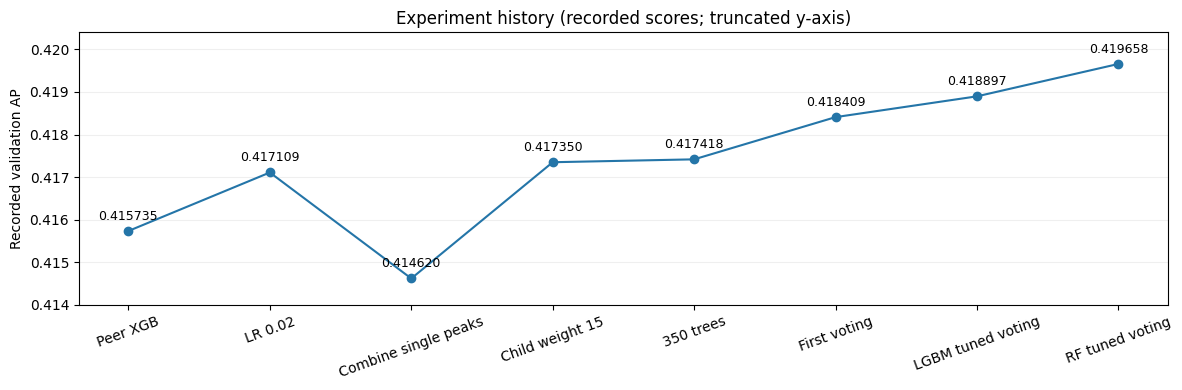

In [10]:
# 과거 기록을 정리한 그래프이며 이 셀에서 튜닝을 다시 수행하지 않습니다.
history = pd.DataFrame({
    "stage": [
        "Peer XGB", "LR 0.02", "Combine single peaks",
        "Child weight 15", "350 trees", "First voting",
        "LGBM tuned voting", "RF tuned voting",
    ],
    "validation_AP": [
        0.4157350922438133, 0.41710873488824773, 0.4146196254677228,
        0.41734980900612745, 0.41741767775310246,
        0.41840910935942266, 0.41889723018291747, 0.4196579357385778,
    ],
})
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(history["stage"], history["validation_AP"], "o-", color="#2475a8")
for i, ap in enumerate(history["validation_AP"]):
    ax.annotate(format(ap, ".6f"), (i, ap), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9)
ax.set_ylim(0.414, 0.4204)
ax.set_ylabel("Recorded validation AP")
ax.set_title("Experiment history (recorded scores; truncated y-axis)")
ax.tick_params(axis="x", labelrotation=20)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## 실행 결과 확인
같은 CSV와 재현 환경에서 최종 AP가 약 **0.419658**이면 기존 최종 모델을 재현한 것입니다. 검증 F1 최대 임계값은 약 **0.654735**, 그때 F1은 약 **0.460425**, 정밀도는 약 **41.08%**, 재현율은 약 **52.37%**였습니다.

모든 셀은 이 파일 안에서 정의한 변수만 사용합니다. 다른 사람에게 전달할 때는 **이 노트북과 원본 cs-training.csv**를 함께 전달하면 됩니다. 실행 결과 폴더와 기존 실험 노트북은 없어도 됩니다. 데이터 파일을 전달할 수 없는 경우에는 같은 원본 파일을 각자 준비하도록 안내하세요.

점수가 달라지면 먼저 CSV 파일 지문, Python·라이브러리 버전, 원본 열 순서와 전처리, 분할 순서, 시드, 모델 파라미터를 확인합니다.